# Proyecto 1 Tecnicas Aprendisaje de Maquina


## Tomas Charria, Emilio Gomez Gomez, Sumin Han, Juan David Nieto


## Preguntas de negocio

1. ¿Existe una relación entre la franja horaria (diurno/nocturno) y la gravedad del accidente? → Tabla de contingencia + chi-cuadrado

2. ¿Los accidentes nocturnos tienden a ser más graves que los diurnos? → Análisis de proporciones y visualización comparativa

3. ¿Hay comunas donde predominan ciertos tipos de vehículos accidentados? → Cruce COMUNA × tipo de vehículo

4. ¿El tipo de propietario del vehículo (particular vs empresa) influye en la gravedad del accidente? → Cruce Propietario de Vehículo x GRAVEDAD

5. ¿Existe correlación entre el número de vehículos involucrados en un accidente y su gravedad? → Correlación de Spearman

6. ¿Los accidentes que involucran peatones son significativamente más graves que los que no los involucran? → Comparación de distribuciones y prueba de hipótesis

| # | Variable | Descripción |
|---|----------|-------------|
| 1 | ORDEN | Identificador secuencial único por registro. |
| 2 | FECHA | Fecha del accidente en formato ISO. |
| 3 | AÑO | Año calendario del accidente (2012–2023). |
| 4 | MES | Mes del accidente con prefijo numérico para ordenamiento cronológico. |
| 5 | DÍA | Día de la semana con prefijo numérico. |
| 6 | GRAVEDAD | Severidad del accidente: Solo daños, Con heridos, Con muertos. Requiere normalización de mayúsculas antes del análisis. |
| 7 | PEATON | Número de peatones involucrados en el accidente. |
| 8 | AUTOMOVIL | Número de automóviles particulares involucrados. |
| 9 | CAMPERO | Número de camperos (SUV/4×4) involucrados. |
| 10 | CAMIONETA | Número de camionetas involucradas. |
| 11 | MICRO | Número de microbuses involucrados. |
| 12 | BUSETA | Número de busetas de transporte público involucradas. |
| 13 | BUS | Número de buses de transporte público involucrados. |
| 14 | CAMION | Número de camiones de carga involucrados. |
| 15 | VOLQUETA | Número de volquetas involucradas. |
| 16 | MOTO | Número de motocicletas involucradas. Es el vehículo con mayor presencia en el dataset. |
| 17 | BICICLETA | Número de bicicletas involucradas. |
| 18 | OTRO | Número de vehículos de categoría no clasificada. |
| 19 | BARRIO | Nombre del barrio donde ocurrió el accidente (texto libre, aproximadamente 200 valores distintos). |
| 20 | HORA | Hora del accidente en formato heredado de Excel. Se debe extraer solo la hora para el análisis. |
| 21 | ENTIDAD | Entidad que registró el accidente: Agentes DTB o Agentes Policía Nacional. |
| 22 | COMUNA | Comuna del municipio donde ocurrió el accidente (14 comunas + No disponible). |
| 23 | Propietario de Vehículo | Tipo de propietario del vehículo: Particular o Empresa. |
| 24 | DIURNIO/NOCTURNO | Franja horaria del accidente: Diurno o Nocturno. El nombre de la columna tiene un error tipográfico. |

Este diccionario sirve como referencia para entender el contenido y las limitaciones de cada variable antes de iniciar el análisis. Permite identificar qué columnas requieren limpieza previa, cuáles son las variables dependientes e independientes según cada pregunta de negocio, y cómo construir variables derivadas como el total de vehículos por accidente a partir de las columnas numéricas individuales.

## Problema 1

### Clasificación: ¿Qué tan grave será un accidente?

Dado el momento del día, el barrio, el tipo de vehículo y la entidad que reporta, ¿se puede predecir si un accidente resultará en solo daños, con heridos o con muertos?

La variable objetivo es GRAVEDAD, con tres clases: Solo daños, Con heridos y Con muertos. El valor práctico de este modelo es la priorización automática del despacho de servicios de emergencia según la probable gravedad del siniestro.

Se implementarán y compararán los siguientes algoritmos: Regresión Logística, Árbol de Decisión, Random Forest, SVM y Gradient Boosted Trees. Las métricas de evaluación serán Accuracy, Precision, Recall, F1-Score (macro y weighted) y AUC-ROC.

## Problema 2

### Regresión: ¿Es posible predecir las frecuencias de accidentes diaria en cada mes?

Mediante este problema se podrá determinar un estimado de frecuencias de accidentes en cada dia para llevar a cabo campañas de concientización y prevención de accidentes, asi como de preparación para cuantos accidentes se estiman atender.



Se compararán regresión lineal y random forest regressor, aplicando PCA previamente para revisar si debe haber una reducción de dimensionalidad. Las métricas de evaluación serán el MSE, RMSE, MAE y el R2.

## Analisis Exploratorio de Datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

url = 'https://github.com/sumin-Han-pnd231/proyecto_MLTecnicas_Accidente_Transito_Bucaramanga/raw/refs/heads/main/3._Accidentes_de_Transito_ocurridos_en_el_Municipio_de_Bucaramanga_20260404.xlsx'


df = pd.read_excel(url)

df.head()

,ORDEN,FECHA,AÑO,MES,DÍA,GRAVEDAD,PEATON,AUTOMOVIL,CAMPERO,CAMIONETA,...,VOLQUETA,MOTO,BICICLETA,OTRO,BARRIO,HORA,ENTIDAD,COMUNA,Propietario de Vehículo,DIURNIO/NOCTURNO
0,1,2012-01-01T00:00:00.000,2012,01. Enero,07. Domingo,Con heridos,0,1,0,0,...,0,0,0,0,Mutis,1899-12-31T12:15:00.000,AGENTES DTB,17. MUTIS,Particular,Diurno
1,2,2012-01-01T00:00:00.000,2012,01. Enero,07. Domingo,Solo daños,0,1,0,1,...,0,0,0,0,Regaderos Norte,1899-12-31T14:00:00.000,AGENTES DTB,02. NORORIENTAL,Empresa,Diurno
2,3,2012-01-01T00:00:00.000,2012,01. Enero,07. Domingo,Solo daños,0,0,0,1,...,0,0,0,0,Cabecera Del Llano,1899-12-31T12:00:00.000,AGENTES DTB,12. CABECERA DEL LLANO,Particular,Diurno
3,4,2012-01-01T00:00:00.000,2012,01. Enero,07. Domingo,Solo daños,0,1,0,1,...,0,0,0,0,Norte Bajo,1899-12-31T18:30:00.000,AGENTES DTB,03. SAN FRANCISCO,Empresa,Nocturno
4,5,2012-01-01T00:00:00.000,2012,01. Enero,07. Domingo,Con heridos,1,0,0,0,...,0,1,0,0,Dangond,1899-12-31T00:30:00.000,AGENTES DTB,11. SUR,Particular,Nocturno


In [2]:
# ── Inventario descriptivo ──────────────────────────────────────
print("TIPOS DE DATOS ")
print(df.dtypes)
print("\n VALORES NULOS ")
print(df.isnull().sum())
print("\n ESTADÍSTICAS BÁSICAS")
df.describe(include='all')

TIPOS DE DATOS 
ORDEN                       int64
FECHA                      object
AÑO                         int64
MES                        object
DÍA                        object
GRAVEDAD                   object
PEATON                      int64
AUTOMOVIL                   int64
CAMPERO                     int64
CAMIONETA                   int64
MICRO                       int64
BUSETA                      int64
BUS                         int64
CAMION                      int64
VOLQUETA                    int64
MOTO                        int64
BICICLETA                   int64
OTRO                        int64
BARRIO                     object
HORA                       object
ENTIDAD                    object
COMUNA                     object
Propietario de Vehículo    object
DIURNIO/NOCTURNO           object
dtype: object

 VALORES NULOS 
ORDEN                      0
FECHA                      0
AÑO                        0
MES                        0
DÍA                  

,ORDEN,FECHA,AÑO,MES,DÍA,GRAVEDAD,PEATON,AUTOMOVIL,CAMPERO,CAMIONETA,...,VOLQUETA,MOTO,BICICLETA,OTRO,BARRIO,HORA,ENTIDAD,COMUNA,Propietario de Vehículo,DIURNIO/NOCTURNO
count,39193.000000,39193,39193.000000,39193,39193,39193,39193.000000,39193.000000,39193.000000,39193.000000,...,39193.000000,39193.000000,39193.000000,39193.000000,39193,39193,39193,39193,39193,39193
unique,NaN,4264,NaN,12,7,4,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,186,1138,2,21,2,2
top,NaN,2013-05-11T00:00:00.000,NaN,03. Marzo,06. Sabado,Solo daños,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,Centro,1899-12-31T16:00:00.000,AGENTES DTB,12. CABECERA DEL LLANO,Particular,Diurno
freq,NaN,26,NaN,3473,6462,19602,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,3861,576,36658,6415,27981,27567
mean,19597.000000,NaN,2016.624550,NaN,NaN,NaN,0.105529,0.781262,0.060368,0.197076,...,0.014033,0.626617,0.017682,0.021279,NaN,NaN,NaN,NaN,NaN,NaN
std,11314.188887,NaN,3.160996,NaN,NaN,NaN,0.340785,0.742035,0.244827,0.431634,...,0.119138,0.654329,0.133333,0.149867,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,2012.000000,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,9799.000000,NaN,2014.000000,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,19597.000000,NaN,2016.000000,NaN,NaN,NaN,0.000000,1.000000,0.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,29395.000000,NaN,2019.000000,NaN,NaN,NaN,0.000000,1.000000,0.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN


#### Antes de explorar, se identifican dos problemas en los datos originales que deben corregirse:

1. **GRAVEDAD** tiene dos formas de escribir el mismo valor: "Con muertos" y "Con Muertos" — se unificarán.
2. **HORA** está almacenada como fecha completa con fecha base ficticia — se extraerá solo la hora numérica.
3. Las columnas de vehículos y PEATON están como texto ("0"/"1") — se convertirán a entero.
4. **AÑO** está como texto — se convertirá a entero.

### Limpieza de datos

In [3]:


#1. Estandarizar Gravedad
df['GRAVEDAD'] = df['GRAVEDAD'].str.strip().str.title()
print("Valores únicos GRAVEDAD:", df['GRAVEDAD'].unique())

# 2. Extraer hora numérica EN HORA
df['HORA_DT'] = pd.to_datetime(df['HORA'], errors='coerce')
df['HORA_NUM'] = df['HORA_DT'].dt.hour + df['HORA_DT'].dt.minute / 60

# 3. Convertir columnas binarias de vehículos a int
cols_vehiculos = ['PEATON','AUTOMOVIL','CAMPERO','CAMIONETA','MICRO',
                  'BUSETA','BUS','CAMION','VOLQUETA','MOTO','BICICLETA','OTRO']
df[cols_vehiculos] = df[cols_vehiculos].apply(pd.to_numeric, errors='coerce').fillna(0).astype(int)

# 4. AÑO a entero
df['AÑO'] = pd.to_numeric(df['AÑO'], errors='coerce').astype('Int64')

# 5. Total de vehículos involucrados por accidente (feature útil)
df['TOTAL_VEHICULOS'] = df[cols_vehiculos].sum(axis=1)

print("\nDataset listo para EDA:")
print(df[['GRAVEDAD','HORA_NUM','AÑO','TOTAL_VEHICULOS']].describe())

Valores únicos GRAVEDAD: ['Con Heridos' 'Solo Daños' 'Con Muertos']

Dataset listo para EDA:
           HORA_NUM         AÑO  TOTAL_VEHICULOS
count  39190.000000     39193.0     39193.000000
mean      13.553045  2016.62455         2.019264
std        5.199975    3.160996         0.448070
min        0.000000      2012.0         1.000000
25%        9.750000      2014.0         2.000000
50%       13.750000      2016.0         2.000000
75%       17.666667      2019.0         2.000000
max       23.983333      2023.0        32.000000


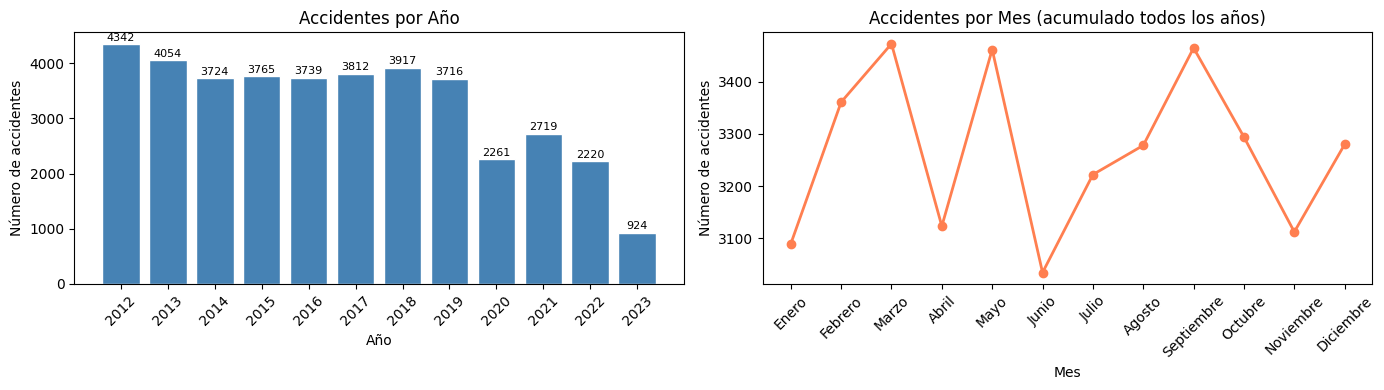


 Se aprecia una caída notable en 2020 (pandemia COVID-19) y una recuperación parcial en 2021-2022.


In [4]:
# 1 — Tendencia anual
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Por año
anual = df.groupby('AÑO').size().reset_index(name='Accidentes')
axes[0].bar(anual['AÑO'].astype(str), anual['Accidentes'], color='steelblue', edgecolor='white')
axes[0].set_title('Accidentes por Año')
axes[0].set_xlabel('Año')
axes[0].set_ylabel('Número de accidentes')
axes[0].tick_params(axis='x', rotation=45)
for bar, val in zip(axes[0].patches, anual['Accidentes']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                 str(val), ha='center', va='bottom', fontsize=8)

# Por mes
orden_meses = sorted(df['MES'].dropna().unique(), key=lambda x: int(x.split('.')[0]))
mensual = df.groupby('MES').size().reindex(orden_meses).reset_index(name='Accidentes')
mensual['MES_CORTO'] = mensual['MES'].str.split('. ').str[1]
axes[1].plot(mensual['MES_CORTO'], mensual['Accidentes'], marker='o', color='coral', linewidth=2)
axes[1].set_title('Accidentes por Mes (acumulado todos los años)')
axes[1].set_xlabel('Mes')
axes[1].set_ylabel('Número de accidentes')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print("\n Se aprecia una caída notable en 2020 (pandemia COVID-19) y una recuperación parcial en 2021-2022.")

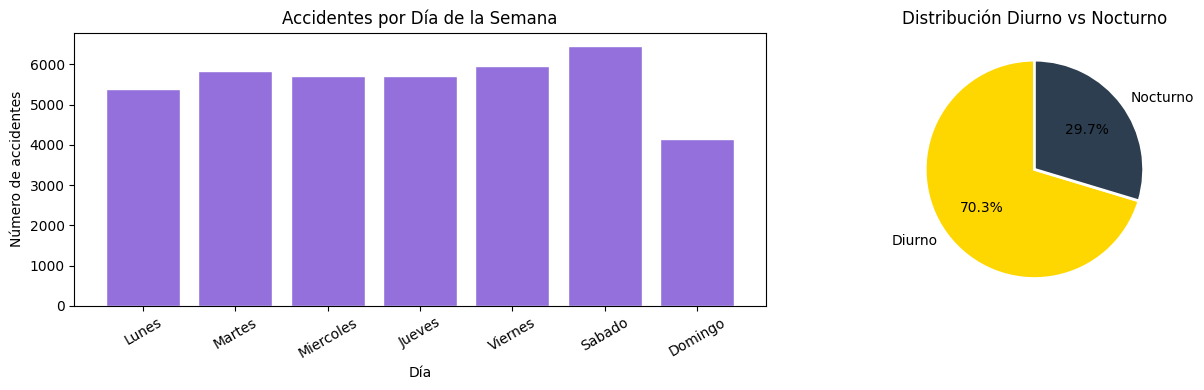

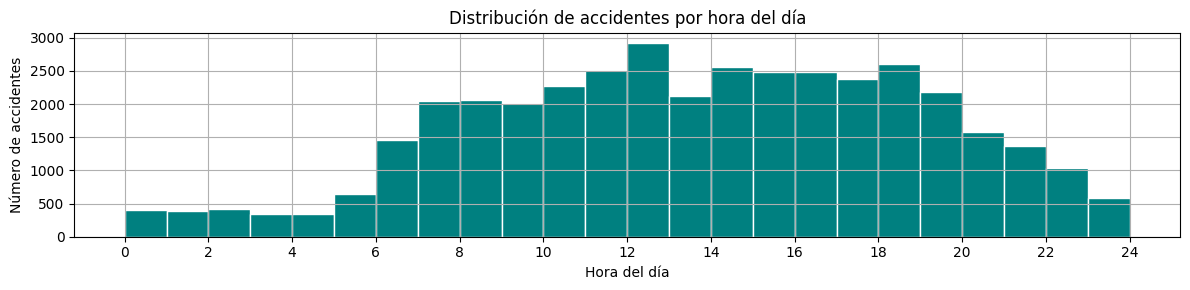

In [5]:
# 2 — Día de la semana y franja horaria
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Por día (lunes a domingo)
orden_dias = sorted(df['DÍA'].dropna().unique(), key=lambda x: int(x.split('.')[0]))
por_dia = df.groupby('DÍA').size().reindex(orden_dias).reset_index(name='Accidentes')
por_dia['DÍA_CORTO'] = por_dia['DÍA'].str.split('. ').str[1]
axes[0].bar(por_dia['DÍA_CORTO'], por_dia['Accidentes'], color='mediumpurple', edgecolor='white')
axes[0].set_title('Accidentes por Día de la Semana')
axes[0].set_xlabel('Día')
axes[0].set_ylabel('Número de accidentes')
axes[0].tick_params(axis='x', rotation=30)

# Por franja Horario
franja = df['DIURNIO/NOCTURNO'].value_counts()
axes[1].pie(franja.values, labels=franja.index, autopct='%1.1f%%',
            colors=['#FFD700','#2C3E50'], startangle=90,
            wedgeprops=dict(edgecolor='white', linewidth=2))
axes[1].set_title('Distribución Diurno vs Nocturno')

plt.tight_layout()
plt.show()

# Distribución de horas
plt.figure(figsize=(12, 3))
df['HORA_NUM'].dropna().hist(bins=24, color='teal', edgecolor='white', range=(0,24))
plt.title('Distribución de accidentes por hora del día')
plt.xlabel('Hora del día')
plt.ylabel('Número de accidentes')
plt.xticks(range(0, 25, 2))
plt.tight_layout()
plt.show()

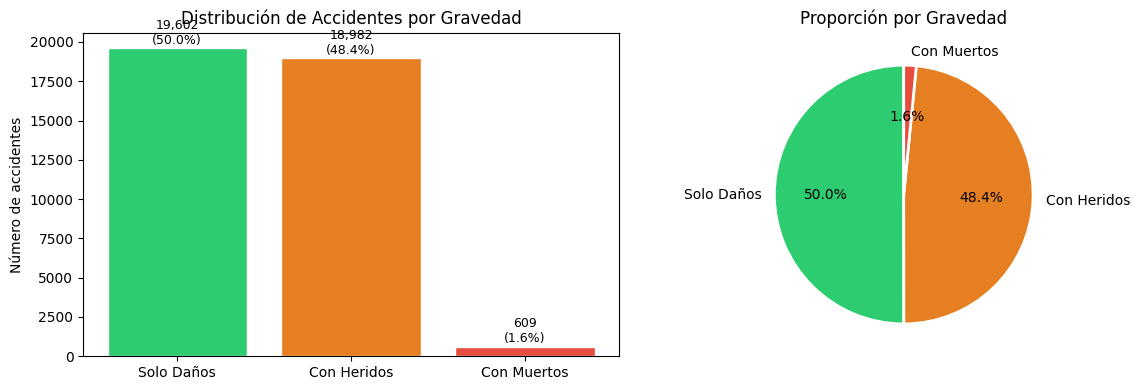

 El data set esta desbalanceado, con una mayoría de accidentes sin muertos, lo que es importante considerar para el modelado predictivo.


In [6]:
# 3 — Distribución de gravedad
gravedad_counts = df['GRAVEDAD'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(gravedad_counts.index, gravedad_counts.values,
            color=['#2ECC71','#E67E22','#E74C3C'], edgecolor='white')
axes[0].set_title('Distribución de Accidentes por Gravedad')
axes[0].set_ylabel('Número de accidentes')
for bar, val in zip(axes[0].patches, gravedad_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 80,
                 f'{val:,}\n({val/len(df)*100:.1f}%)', ha='center', va='bottom', fontsize=9)

axes[1].pie(gravedad_counts.values, labels=gravedad_counts.index, autopct='%1.1f%%',
            colors=['#2ECC71','#E67E22','#E74C3C'], startangle=90,
            wedgeprops=dict(edgecolor='white', linewidth=2))
axes[1].set_title('Proporción por Gravedad')

plt.tight_layout()
plt.show()


print(" El data set esta desbalanceado, con una mayoría de accidentes sin muertos, lo que es importante considerar para el modelado predictivo.")

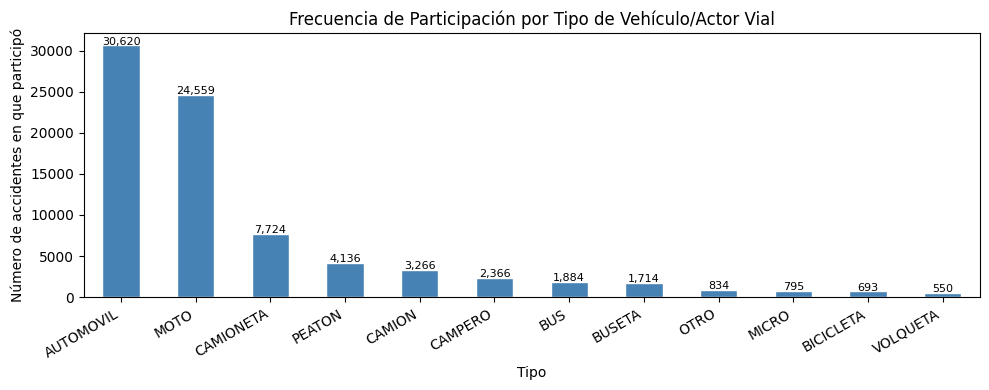


Medidas de tendencia central y dispersión — participación por tipo:
count       12.0
mean      6595.1
std      10092.4
min        550.0
25%        824.2
50%       2125.0
75%       5033.0
max      30620.0
dtype: float64


In [7]:
# 4 — Tipos de vehículo involucrados
participacion = df[cols_vehiculos].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 4))
participacion.plot(kind='bar', color='steelblue', edgecolor='white')
plt.title('Frecuencia de Participación por Tipo de Vehículo/Actor Vial')
plt.xlabel('Tipo')
plt.ylabel('Número de accidentes en que participó')
plt.xticks(rotation=30, ha='right')
for i, val in enumerate(participacion.values):
    plt.text(i, val + 100, f'{val:,}', ha='center', fontsize=8)
plt.tight_layout()
plt.show()

print("\nMedidas de tendencia central y dispersión — participación por tipo:")
print(participacion.describe().round(1))

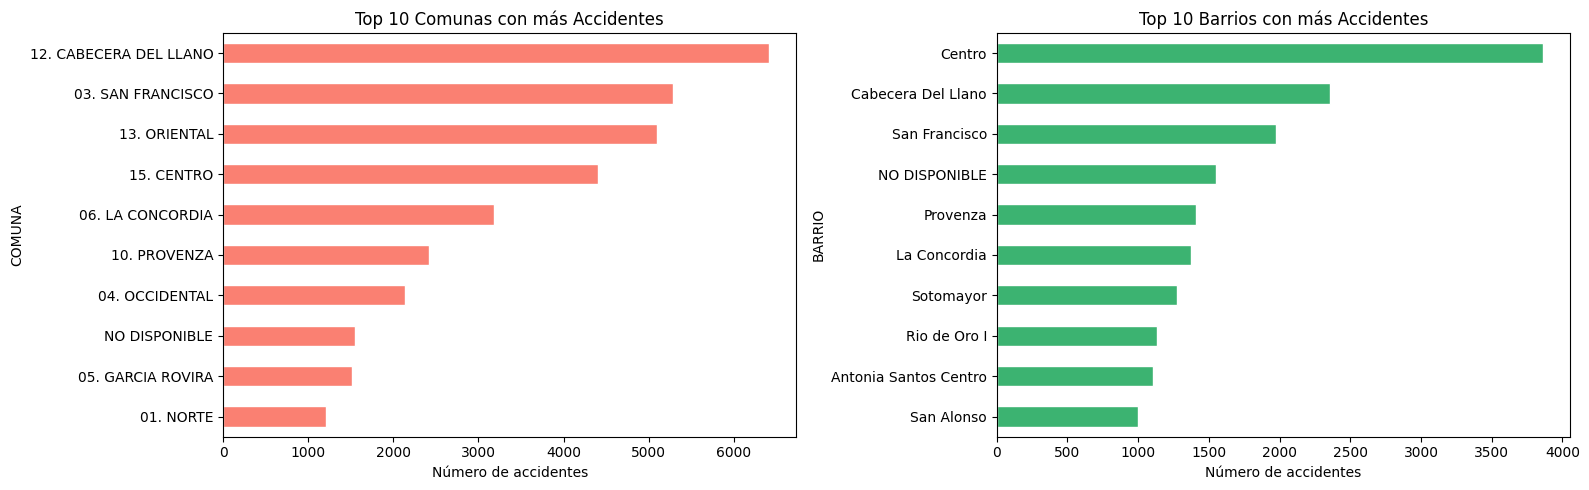

In [8]:
# 5 — Top comunas y barrios
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

top_comunas = df['COMUNA'].value_counts().head(10)
top_comunas.plot(kind='barh', ax=axes[0], color='salmon', edgecolor='white')
axes[0].set_title('Top 10 Comunas con más Accidentes')
axes[0].set_xlabel('Número de accidentes')
axes[0].invert_yaxis()

top_barrios = df['BARRIO'].value_counts().head(10)
top_barrios.plot(kind='barh', ax=axes[1], color='mediumseagreen', edgecolor='white')
axes[1].set_title('Top 10 Barrios con más Accidentes')
axes[1].set_xlabel('Número de accidentes')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

Accidentes con peatón involucrado:    4,136  (10.6%)
Accidentes sin peatón involucrado:    35,057  (89.4%)


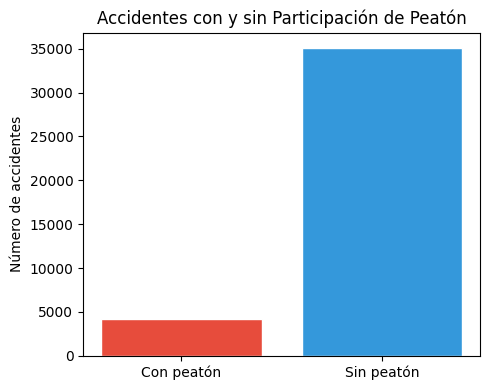

In [9]:
# 6 — Proporción de accidentes con peatones
con_peaton = df['PEATON'].sum()
sin_peaton = len(df) - con_peaton

print(f"Accidentes con peatón involucrado:    {con_peaton:,}  ({con_peaton/len(df)*100:.1f}%)")
print(f"Accidentes sin peatón involucrado:    {sin_peaton:,}  ({sin_peaton/len(df)*100:.1f}%)")

plt.figure(figsize=(5, 4))
plt.bar(['Con peatón', 'Sin peatón'], [con_peaton, sin_peaton],
        color=['#E74C3C','#3498DB'], edgecolor='white')
plt.title('Accidentes con y sin Participación de Peatón')
plt.ylabel('Número de accidentes')
plt.tight_layout()
plt.show()

=== Proporción de gravedad según franja horaria (%) ===
GRAVEDAD          Con Heridos  Con Muertos  Solo Daños
DIURNIO/NOCTURNO                                      
Diurno                  46.43         1.11       52.46
Nocturno                53.18         2.60       44.22

Chi-cuadrado = 303.86  |  p-valor = 0.0000  |  GL = 2
Interpretación: Existe asociación estadísticamente significativa.


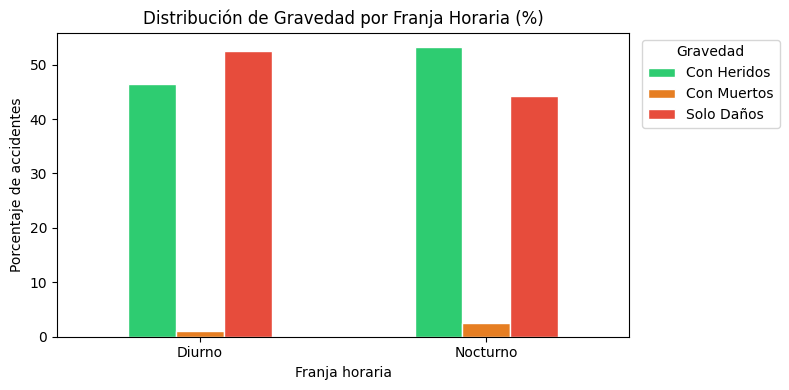

In [10]:

contingencia_franja = pd.crosstab(df['DIURNIO/NOCTURNO'], df['GRAVEDAD'], normalize='index') * 100
print("=== Proporción de gravedad según franja horaria (%) ===")
print(contingencia_franja.round(2))


ct_abs = pd.crosstab(df['DIURNIO/NOCTURNO'], df['GRAVEDAD'])
chi2, p, dof, expected = stats.chi2_contingency(ct_abs)
print(f"\nChi-cuadrado = {chi2:.2f}  |  p-valor = {p:.4f}  |  GL = {dof}")
print("Interpretación:", "Existe asociación estadísticamente significativa." if p < 0.05
      else "No hay evidencia de asociación significativa.")

# Visualización
contingencia_franja.plot(kind='bar', figsize=(8, 4), edgecolor='white',
                         color=['#2ECC71','#E67E22','#E74C3C'])
plt.title('Distribución de Gravedad por Franja Horaria (%)')
plt.ylabel('Porcentaje de accidentes')
plt.xlabel('Franja horaria')
plt.xticks(rotation=0)
plt.legend(title='Gravedad', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

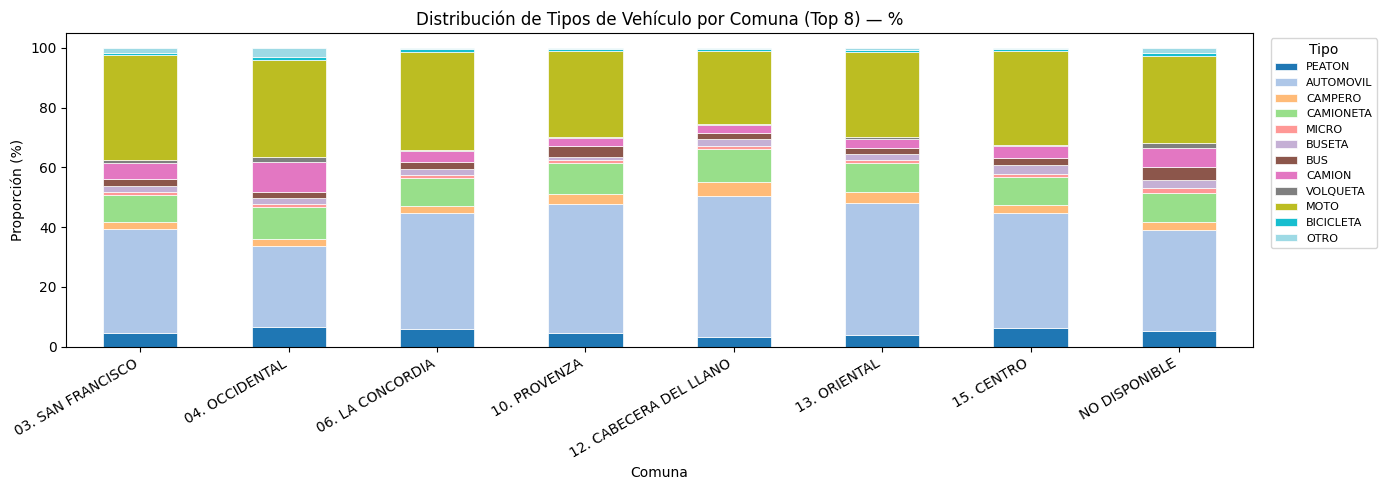

In [11]:
# Top 8 comunas vs tipo de vehículo
top8_comunas = df['COMUNA'].value_counts().head(8).index
df_top = df[df['COMUNA'].isin(top8_comunas)]
comunas_vehiculos = df_top.groupby('COMUNA')[cols_vehiculos].sum()

# Normalizar por fila para ver proporciones
comunas_vehiculos_norm = comunas_vehiculos.div(comunas_vehiculos.sum(axis=1), axis=0) * 100

plt.figure(figsize=(14, 5))
comunas_vehiculos_norm.plot(kind='bar', stacked=True, ax=plt.gca(),
                            colormap='tab20', edgecolor='white', linewidth=0.5)
plt.title('Distribución de Tipos de Vehículo por Comuna (Top 8) — %')
plt.ylabel('Proporción (%)')
plt.xlabel('Comuna')
plt.xticks(rotation=30, ha='right')
plt.legend(title='Tipo', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

=== Proporción de gravedad según tipo de propietario (%) ===
GRAVEDAD                 Con Heridos  Con Muertos  Solo Daños
Propietario de Vehículo                                      
Empresa                        40.36         1.56       58.08
Particular                     51.67         1.55       46.78


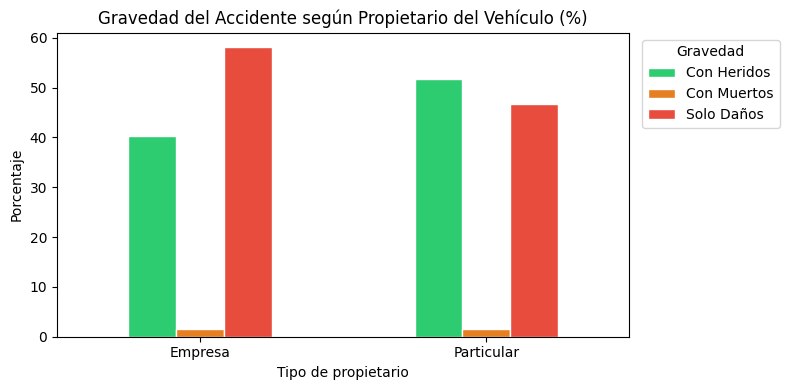


Chi-cuadrado = 415.69  |  p-valor = 0.0000
Interpretación: Asociación estadísticamente significativa.


In [12]:
ct_prop = pd.crosstab(df['Propietario de Vehículo'], df['GRAVEDAD'], normalize='index') * 100
print("=== Proporción de gravedad según tipo de propietario (%) ===")
print(ct_prop.round(2))

ct_prop.plot(kind='bar', figsize=(8, 4), edgecolor='white',
             color=['#2ECC71','#E67E22','#E74C3C'])
plt.title('Gravedad del Accidente según Propietario del Vehículo (%)')
plt.ylabel('Porcentaje')
plt.xlabel('Tipo de propietario')
plt.xticks(rotation=0)
plt.legend(title='Gravedad', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df['Propietario de Vehículo'], df['GRAVEDAD']))
print(f"\nChi-cuadrado = {chi2:.2f}  |  p-valor = {p:.4f}")
print("Interpretación:", "Asociación estadísticamente significativa." if p < 0.05
      else "Sin evidencia de asociación significativa.")

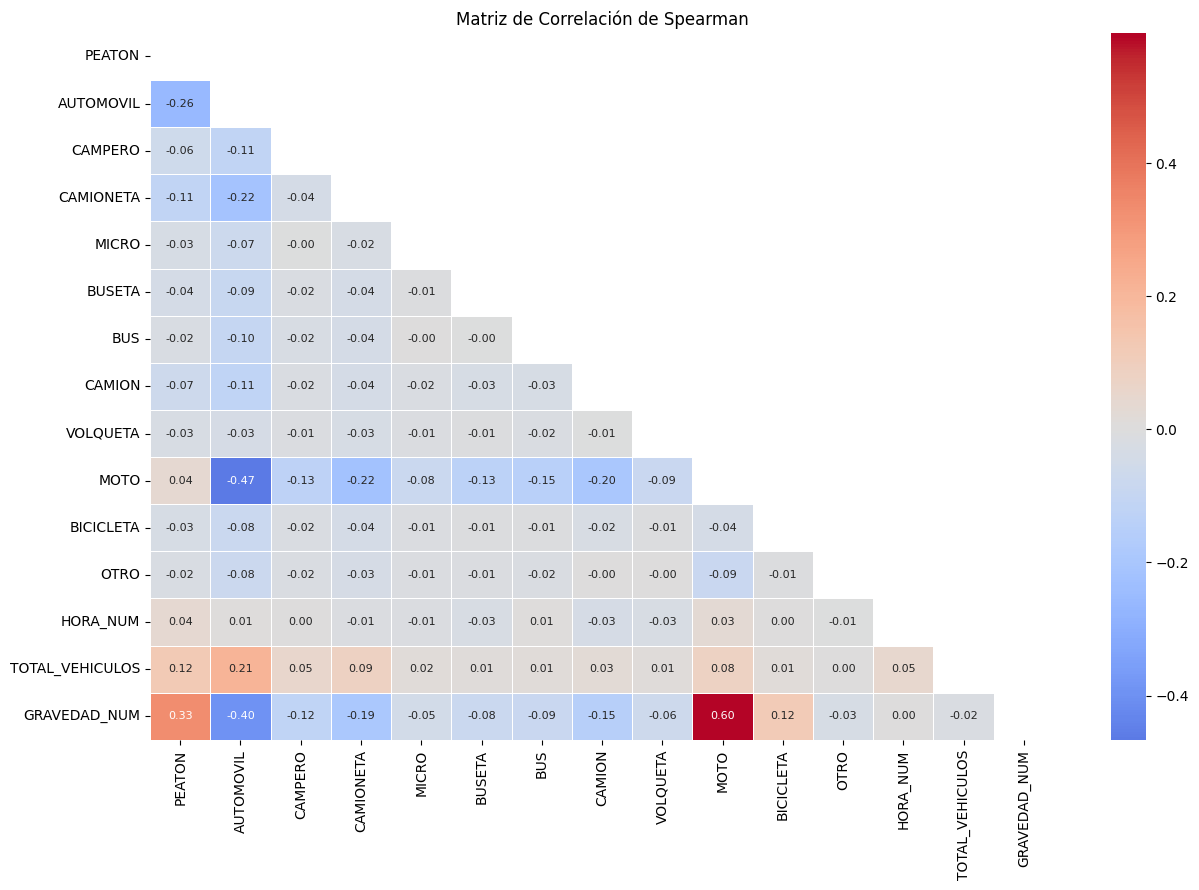


Correlaciones con GRAVEDAD_NUM (ordenadas):
MOTO               0.596
PEATON             0.332
BICICLETA          0.118
HORA_NUM           0.001
TOTAL_VEHICULOS   -0.016
OTRO              -0.031
MICRO             -0.049
VOLQUETA          -0.064
BUSETA            -0.081
BUS               -0.086
CAMPERO           -0.118
CAMION            -0.149
CAMIONETA         -0.192
AUTOMOVIL         -0.398
Name: GRAVEDAD_NUM, dtype: float64


In [13]:
df['GRAVEDAD_NUM'] = df['GRAVEDAD'].map({'Solo Daños': 0, 'Con Heridos': 1, 'Con Muertos': 2})

cols_corr = cols_vehiculos + ['HORA_NUM', 'TOTAL_VEHICULOS', 'GRAVEDAD_NUM']
corr_matrix = df[cols_corr].corr(method='spearman')

plt.figure(figsize=(13, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, annot_kws={'size': 8})
plt.title('Matriz de Correlación de Spearman')
plt.tight_layout()
plt.show()

print("\nCorrelaciones con GRAVEDAD_NUM (ordenadas):")
print(corr_matrix['GRAVEDAD_NUM'].drop('GRAVEDAD_NUM').sort_values(ascending=False).round(3))

In [14]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

df_model = df.copy()

#    Solo daños = 0 - Con heridos = 1 - Con muertos = 2
df_model['GRAVEDAD_NUM'] = df_model['GRAVEDAD'].map(
    {'Solo Daños': 0, 'Con Heridos': 1, 'Con Muertos': 2})
print("Distribución de clases:")
print(df_model['GRAVEDAD_NUM'].value_counts().sort_index())

#  Extraer número de mes y día desde los campos de texto
df_model['MES_NUM'] = df_model['MES'].str.split('. ').str[0].astype(int)
df_model['DIA_NUM'] = df_model['DÍA'].str.split('. ').str[0].astype(int)

#  Codificar DIURNIO/NOCTURNO como binario
df_model['ES_NOCTURNO'] = (df_model['DIURNIO/NOCTURNO'] == 'Nocturno').astype(int)

#  Codificar ENTIDAD como binario (DTB = 0, Policia = 1)
df_model['ENTIDAD_NUM'] = (df_model['ENTIDAD'] == 'AGENTES POLICIA NACIONAL').astype(int)

#  Codificar PROPIETARIO como binario
df_model['ES_EMPRESA'] = (df_model['Propietario de Vehículo'] == 'Empresa').astype(int)

#  Codificar COMUNA con Label Encoding (21 categorías — manejable)
le_comuna = LabelEncoder()
df_model['COMUNA_ENC'] = le_comuna.fit_transform(df_model['COMUNA'].fillna('Desconocido'))

#  AÑO ya es numérico — se incluye para capturar tendencias temporales

#  Selección final de features
features = (cols_vehiculos +
            ['HORA_NUM', 'MES_NUM', 'DIA_NUM', 'ES_NOCTURNO',
             'ENTIDAD_NUM', 'ES_EMPRESA', 'COMUNA_ENC',
             'TOTAL_VEHICULOS', 'AÑO'])

X = df_model[features].copy()
y = df_model['GRAVEDAD_NUM'].copy()

mask_valid = y.notna()
X, y = X[mask_valid], y[mask_valid]
y = y.astype(int)

X = X.fillna(X.median())

print(f"\nDataset final: {X.shape[0]:,} filas × {X.shape[1]} features")
print("Features:", features)

Distribución de clases:
GRAVEDAD_NUM
0    19602
1    18982
2      609
Name: count, dtype: int64

Dataset final: 39,193 filas × 21 features
Features: ['PEATON', 'AUTOMOVIL', 'CAMPERO', 'CAMIONETA', 'MICRO', 'BUSETA', 'BUS', 'CAMION', 'VOLQUETA', 'MOTO', 'BICICLETA', 'OTRO', 'HORA_NUM', 'MES_NUM', 'DIA_NUM', 'ES_NOCTURNO', 'ENTIDAD_NUM', 'ES_EMPRESA', 'COMUNA_ENC', 'TOTAL_VEHICULOS', 'AÑO']


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Entrenamiento: {X_train.shape[0]:,} registros")
print(f"Prueba:        {X_test.shape[0]:,} registros")
print("\nDistribución de clases en entrenamiento:")
print(pd.Series(y_train).value_counts().sort_index()
      .rename({0:'Solo daños', 1:'Con heridos', 2:'Con muertos'}))
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

Entrenamiento: 31,354 registros
Prueba:        7,839 registros

Distribución de clases en entrenamiento:
GRAVEDAD_NUM
Solo daños     15681
Con heridos    15186
Con muertos      487
Name: count, dtype: int64


##### Como la base de datos no esta balanceada hay que balancear

In [16]:

from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42, sampling_strategy='not majority')
X_train_bal, y_train_bal = smote.fit_resample(X_train_sc, y_train)

labels = {0: 'Solo daños', 1: 'Con heridos', 2: 'Con muertos'}

print("Distribución de clases ANTES de Balanceo:")
print(pd.Series(y_train).value_counts().sort_index().rename(index=labels))
print("\nDistribución de clases DESPUÉS de Balanceo:")
print(pd.Series(y_train_bal).value_counts().sort_index().rename(index=labels))


Distribución de clases ANTES de Balanceo:
GRAVEDAD_NUM
Solo daños     15681
Con heridos    15186
Con muertos      487
Name: count, dtype: int64

Distribución de clases DESPUÉS de Balanceo:
GRAVEDAD_NUM
Solo daños     15681
Con heridos    15681
Con muertos    15681
Name: count, dtype: int64


#### Regresión Logística


  Regresión Logística
  Accuracy : 0.7091
  F1-Score : 0.7527  (weighted)
  AUC-ROC  : 0.8768  (OvR weighted)

              precision    recall  f1-score   support

  Solo daños       0.89      0.76      0.82      3921
 Con heridos       0.75      0.65      0.70      3796
 Con muertos       0.07      0.72      0.13       122

    accuracy                           0.71      7839
   macro avg       0.57      0.71      0.55      7839
weighted avg       0.81      0.71      0.75      7839



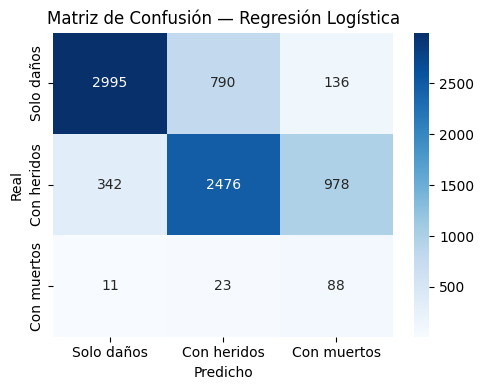

In [17]:
# Regresión Logística
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score, roc_auc_score)
from sklearn.preprocessing import label_binarize

def evaluar_modelo(nombre, modelo, X_tr, y_tr, X_te, y_te):
    """Entrena, predice y muestra métricas + matriz de confusión."""
    modelo.fit(X_tr, y_tr)
    y_pred = modelo.predict(X_te)
    acc    = accuracy_score(y_te, y_pred)
    f1     = f1_score(y_te, y_pred, average='weighted')

    # AUC multiclase (OvR)
    if hasattr(modelo, 'predict_proba'):
        y_prob = modelo.predict_proba(X_te)
        auc = roc_auc_score(label_binarize(y_te, classes=[0,1,2]),
                            y_prob, multi_class='ovr', average='weighted')
    else:
        auc = float('nan')

    print(f"\n{'='*55}")
    print(f"  {nombre}")
    print(f"{'='*55}")
    print(f"  Accuracy : {acc:.4f}")
    print(f"  F1-Score : {f1:.4f}  (weighted)")
    print(f"  AUC-ROC  : {auc:.4f}  (OvR weighted)")
    print(f"\n{classification_report(y_te, y_pred, target_names=['Solo daños','Con heridos','Con muertos'])}")

    # Matriz de confusión
    cm = confusion_matrix(y_te, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Solo daños','Con heridos','Con muertos'],
                yticklabels=['Solo daños','Con heridos','Con muertos'])
    plt.title(f'Matriz de Confusión — {nombre}')
    plt.ylabel('Real')
    plt.xlabel('Predicho')
    plt.tight_layout()
    plt.show()

    return {'Modelo': nombre, 'Accuracy': acc, 'F1 Weighted': f1, 'AUC-ROC': auc}

# ── Modelo 1: Regresión Logística ──────────────────────────────
rl = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
res_rl = evaluar_modelo('Regresión Logística', rl, X_train_bal, y_train_bal, X_test_sc, y_test)

#### Optimización de Regresión Logística con RandomizedSearchCV

Fitting 5 folds for each of 5 candidates, totalling 25 fits

Mejores hiperparámetros para Regresión Logística: {'C': np.float64(0.006026889128682512), 'penalty': 'l1', 'solver': 'liblinear'}

  Regresión Logística Optimizada (RandomSearch)
  Accuracy : 0.7019
  F1-Score : 0.7484  (weighted)
  AUC-ROC  : 0.8699  (OvR weighted)

              precision    recall  f1-score   support

  Solo daños       0.90      0.77      0.83      3921
 Con heridos       0.75      0.63      0.69      3796
 Con muertos       0.07      0.75      0.13       122

    accuracy                           0.70      7839
   macro avg       0.57      0.72      0.55      7839
weighted avg       0.81      0.70      0.75      7839



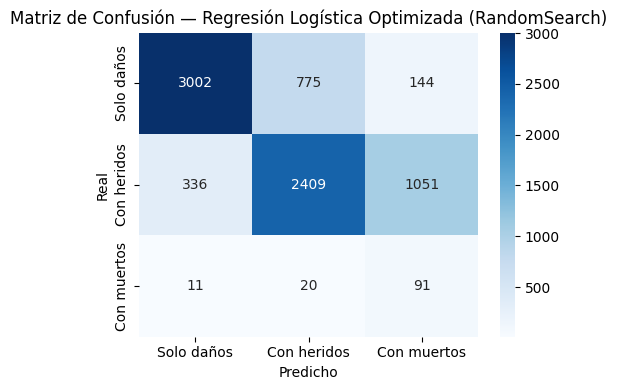

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

# Definir la distribución de hiperparámetros para RandomizedSearchCV para LogisticRegression
param_dist_lr = {
    'C': loguniform(0.001, 100), # Parámetro de regularización (log-uniform para explorar un amplio rango)
    'solver': ['liblinear', 'saga'], # Solvers that support different penalties
    'penalty': ['l1', 'l2'], # L1 or L2 regularization
}

# Inicializar el clasificador de Regresión Logística
lr_base = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)

# Configurar RandomizedSearchCV para LogisticRegression
random_search_lr = RandomizedSearchCV(
    estimator=lr_base,
    param_distributions=param_dist_lr,
    n_iter=5, # Número de combinaciones a probar
    cv=5,
    scoring='f1_weighted',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Ejecutar la búsqueda aleatoria en los datos de entrenamiento balanceados
random_search_lr.fit(X_train_bal, y_train_bal)

# Mostrar los mejores hiperparámetros encontrados
print(f"\nMejores hiperparámetros para Regresión Logística: {random_search_lr.best_params_}")

# Evaluar el mejor modelo encontrado
lr_optimized = random_search_lr.best_estimator_
res_lr_opt = evaluar_modelo('Regresión Logística Optimizada (RandomSearch)', lr_optimized, X_train_bal, y_train_bal, X_test_sc, y_test)

#### Árbol de Decision


  Árbol de Decisión
  Accuracy : 0.7865
  F1-Score : 0.8019  (weighted)
  AUC-ROC  : 0.8722  (OvR weighted)

              precision    recall  f1-score   support

  Solo daños       0.90      0.77      0.83      3921
 Con heridos       0.77      0.82      0.79      3796
 Con muertos       0.07      0.27      0.12       122

    accuracy                           0.79      7839
   macro avg       0.58      0.62      0.58      7839
weighted avg       0.83      0.79      0.80      7839



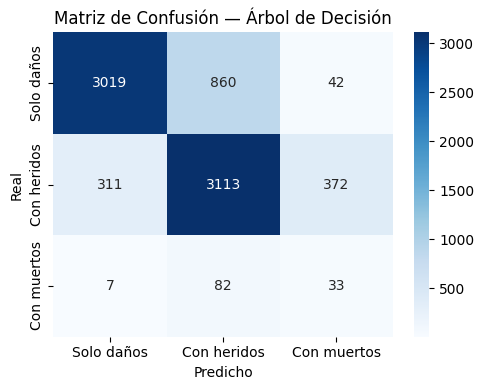

In [19]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42, class_weight='balanced', max_depth=10)
res_dt = evaluar_modelo('Árbol de Decisión', dt, X_train_bal, y_train_bal, X_test_sc, y_test)

#### Optimización de Árbol de Decisión con RandomizedSearchCV

Fitting 5 folds for each of 50 candidates, totalling 250 fits

Mejores hiperparámetros para el Árbol de Decisión: {'criterion': 'entropy', 'max_depth': 31, 'min_samples_leaf': 9, 'min_samples_split': 6}

  Árbol de Decisión Optimizado (RandomSearch)
  Accuracy : 0.7871
  F1-Score : 0.7919  (weighted)
  AUC-ROC  : 0.8676  (OvR weighted)

              precision    recall  f1-score   support

  Solo daños       0.83      0.82      0.82      3921
 Con heridos       0.79      0.78      0.78      3796
 Con muertos       0.09      0.18      0.12       122

    accuracy                           0.79      7839
   macro avg       0.57      0.59      0.58      7839
weighted avg       0.80      0.79      0.79      7839



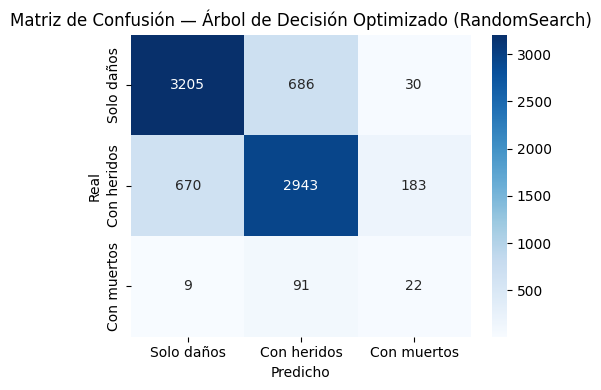

In [20]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

# Definir la distribución de hiperparámetros para RandomizedSearchCV
param_dist = {
    'max_depth': randint(5, 50), # Profundidad máxima del árbol
    'min_samples_split': randint(2, 20), # Número mínimo de muestras requeridas para dividir un nodo interno
    'min_samples_leaf': randint(1, 10), # Número mínimo de muestras requeridas para ser un nodo hoja
    'criterion': ['gini', 'entropy'] # Función para medir la calidad de una división
}

# Inicializar el clasificador de árbol de decisión (con class_weight='balanced')
dt_base = DecisionTreeClassifier(random_state=42, class_weight='balanced')

# Configurar RandomizedSearchCV
# n_iter: número de combinaciones de hiperparámetros a probar
# cv: número de pliegues en la validación cruzada
# scoring: métrica a optimizar (f1_weighted es adecuado para clases desbalanceadas)
# verbose: controla la verbosidad de la salida
# n_jobs: número de trabajos a ejecutar en paralelo (-1 usa todos los procesadores)
random_search_dt = RandomizedSearchCV(
    estimator=dt_base,
    param_distributions=param_dist,
    n_iter=50, # Puedes ajustar este número para un balance entre tiempo y exploración
    cv=5,
    scoring='f1_weighted',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Ejecutar la búsqueda aleatoria en los datos de entrenamiento balanceados
random_search_dt.fit(X_train_bal, y_train_bal)

# Mostrar los mejores hiperparámetros encontrados
print(f"\nMejores hiperparámetros para el Árbol de Decisión: {random_search_dt.best_params_}")

# Evaluar el mejor modelo encontrado
dt_optimized = random_search_dt.best_estimator_
res_dt_opt = evaluar_modelo('Árbol de Decisión Optimizado (RandomSearch)', dt_optimized, X_train_bal, y_train_bal, X_test_sc, y_test)

#### SVM


  SVM (RBF)
  Accuracy : 0.7666
  F1-Score : 0.7914  (weighted)
  AUC-ROC  : 0.8705  (OvR weighted)

              precision    recall  f1-score   support

  Solo daños       0.90      0.78      0.84      3921
 Con heridos       0.77      0.76      0.77      3796
 Con muertos       0.09      0.48      0.15       122

    accuracy                           0.77      7839
   macro avg       0.59      0.68      0.58      7839
weighted avg       0.83      0.77      0.79      7839



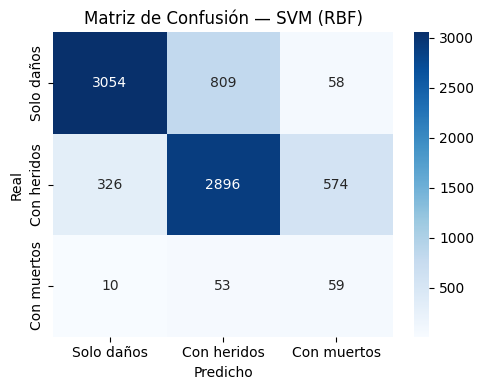

In [21]:
from sklearn.svm import SVC

svm = SVC(kernel='rbf', probability=True, random_state=42, class_weight='balanced')
res_svm = evaluar_modelo('SVM (RBF)', svm, X_train_bal, y_train_bal, X_test_sc, y_test)

#### Optimización de SVM con RandomizedSearchCV

Fitting 3 folds for each of 3 candidates, totalling 9 fits

Mejores hiperparámetros para SVM: {'kernel': 'rbf', 'gamma': 'auto', 'C': 100}

  SVM Optimizado (RandomSearch)
  Accuracy : 0.7866
  F1-Score : 0.7981  (weighted)
  AUC-ROC  : 0.8653  (OvR weighted)

              precision    recall  f1-score   support

  Solo daños       0.88      0.77      0.82      3921
 Con heridos       0.77      0.82      0.79      3796
 Con muertos       0.08      0.25      0.13       122

    accuracy                           0.79      7839
   macro avg       0.58      0.61      0.58      7839
weighted avg       0.82      0.79      0.80      7839



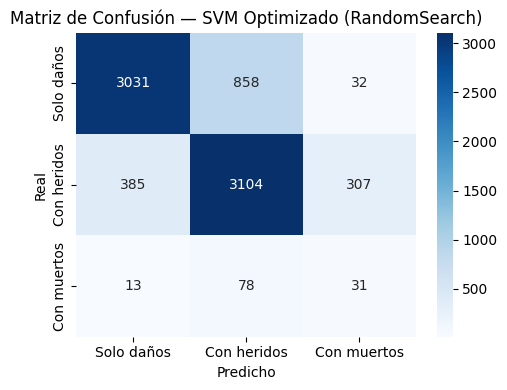

In [22]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, loguniform
from sklearn.svm import SVC

# Definir la distribución de hiperparámetros para RandomizedSearchCV para SVM
param_dist_svm = {
    'C': [0.1, 100], # Parámetro de regularización (valores discretos)
    'gamma': ['scale', 'auto'], # Coeficiente del kernel
    'kernel': ['rbf'] # Tipo de kernel
}

# Inicializar el clasificador SVM (con class_weight='balanced')
svm_base = SVC(random_state=42, class_weight='balanced', probability=True)

# Configurar RandomizedSearchCV para SVM
random_search_svm = RandomizedSearchCV(
    estimator=svm_base,
    param_distributions=param_dist_svm,
    n_iter=3, # Usar un n_iter más bajo para reducir el tiempo de ejecución si es muy lento
    cv=3, # Usar un cv más bajo para reducir el tiempo de ejecución si es muy lento
    scoring='f1_weighted',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Ejecutar la búsqueda aleatoria en los datos de entrenamiento balanceados
random_search_svm.fit(X_train_bal, y_train_bal)

# Mostrar los mejores hiperparámetros encontrados
print(f"\nMejores hiperparámetros para SVM: {random_search_svm.best_params_}")

# Evaluar el mejor modelo encontrado
svm_optimized = random_search_svm.best_estimator_
res_svm_opt = evaluar_modelo('SVM Optimizado (RandomSearch)', svm_optimized, X_train_bal, y_train_bal, X_test_sc, y_test)

#### GB Classifier


  Gradient Boosted Trees
  Accuracy : 0.8312
  F1-Score : 0.8279  (weighted)
  AUC-ROC  : 0.9091  (OvR weighted)

              precision    recall  f1-score   support

  Solo daños       0.89      0.80      0.84      3921
 Con heridos       0.79      0.89      0.84      3796
 Con muertos       0.27      0.10      0.14       122

    accuracy                           0.83      7839
   macro avg       0.65      0.60      0.61      7839
weighted avg       0.83      0.83      0.83      7839



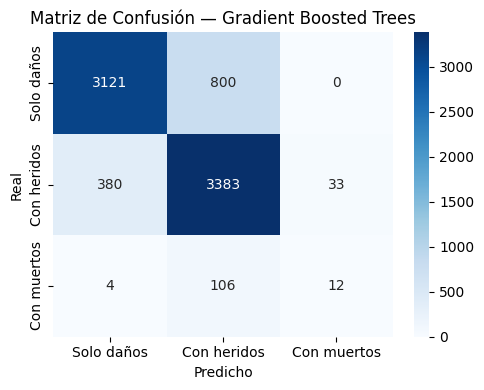

In [23]:
from sklearn.ensemble import GradientBoostingClassifier

gbt = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1,
                                  max_depth=5, random_state=42)
res_gbt = evaluar_modelo('Gradient Boosted Trees', gbt, X_train_bal, y_train_bal, X_test_sc, y_test)

#### Optimización de Gradient Boosting con RandomizedSearchCV

Fitting 5 folds for each of 5 candidates, totalling 25 fits

Mejores hiperparámetros para Gradient Boosting: {'learning_rate': np.float64(0.0849080237694725), 'max_depth': 7, 'min_samples_leaf': 8, 'min_samples_split': 8, 'n_estimators': 171, 'subsample': np.float64(0.662397808134481)}

  Gradient Boosting Optimizado (RandomSearch)
  Accuracy : 0.8315
  F1-Score : 0.8268  (weighted)
  AUC-ROC  : 0.9077  (OvR weighted)

              precision    recall  f1-score   support

  Solo daños       0.88      0.81      0.84      3921
 Con heridos       0.79      0.88      0.84      3796
 Con muertos       0.27      0.05      0.08       122

    accuracy                           0.83      7839
   macro avg       0.65      0.58      0.59      7839
weighted avg       0.83      0.83      0.83      7839



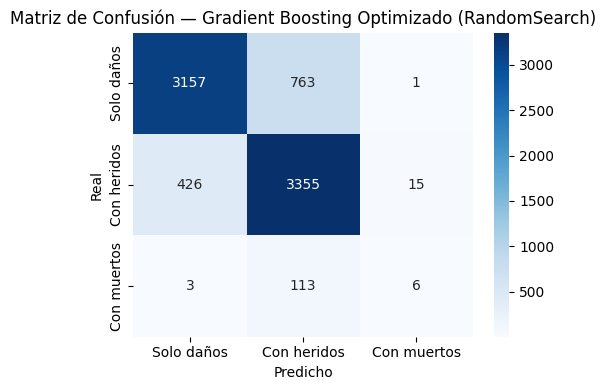

In [24]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

# Definir la distribución de hiperparámetros para RandomizedSearchCV para GBT
param_dist_gbt = {
    'n_estimators': randint(50, 300), # Número de estimadores
    'learning_rate': uniform(0.01, 0.2), # Tasa de aprendizaje
    'max_depth': randint(3, 10), # Profundidad máxima del árbol
    'subsample': uniform(0.6, 0.4), # Submuestra de datos para cada estimador
    'min_samples_split': randint(2, 20),
    'min_samples_leaf': randint(1, 10)
}

# Inicializar el clasificador GBT
gbt_base = GradientBoostingClassifier(random_state=42)

# Configurar RandomizedSearchCV para GBT
random_search_gbt = RandomizedSearchCV(
    estimator=gbt_base,
    param_distributions=param_dist_gbt,
    n_iter=5,
    cv=5,
    scoring='f1_weighted',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Ejecutar la búsqueda aleatoria en los datos de entrenamiento balanceados
random_search_gbt.fit(X_train_bal, y_train_bal)

# Mostrar los mejores hiperparámetros encontrados
print(f"\nMejores hiperparámetros para Gradient Boosting: {random_search_gbt.best_params_}")

# Evaluar el mejor modelo encontrado
gbt_optimized = random_search_gbt.best_estimator_
res_gbt_opt = evaluar_modelo('Gradient Boosting Optimizado (RandomSearch)', gbt_optimized, X_train_bal, y_train_bal, X_test_sc, y_test)

Según los diferentes modelos, el mejor modelo es el Gradient Boosting Optimizado con hiperparametros 0.13 de taza de aprendizaje, produndidad maxima de 4, min sample leafs de 6, ,in sample split de 13, 138 numero de estimadores, un subsample de 0.7165

In [25]:
import joblib

# Define the filename for the exported model
model_filename = 'gbt_optimized_model.pkl'

# Save the model to disk
joblib.dump(gbt_optimized, model_filename)

print(f"Optimized Gradient Boosting model exported successfully to '{model_filename}'")

Optimized Gradient Boosting model exported successfully to 'gbt_optimized_model.pkl'


## Problema 2: Regresión - Predicción de Frecuencias de Accidentes

Para este problema, el objetivo es predecir las frecuencias de accidentes por comuna en distintas franjas horarias. Crearemos un dataset agregando los accidentes por año, mes, día, comuna y si es diurno/nocturno, y la variable objetivo será el conteo de accidentes para cada combinación.

In [26]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

def evaluar_regresor(nombre, modelo, X_tr, y_tr, X_te, y_te):
    """Entrena, predice y muestra métricas de regresión."""
    modelo.fit(X_tr, y_tr)
    y_pred = modelo.predict(X_te)

    mse = mean_squared_error(y_te, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_te, y_pred)
    r2 = r2_score(y_te, y_pred)

    print(f"\n{'='*55}")
    print(f"  {nombre}")
    print(f"{'='*55}")
    print(f"  MSE  : {mse:.4f}")
    print(f"  RMSE : {rmse:.4f}")
    print(f"  MAE  : {mae:.4f}")
    print(f"  R2   : {r2:.4f}")

    return {'Modelo': nombre, 'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R2': r2}

In [27]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Inicializar PCA
pca = PCA()

# Ajustar PCA a los datos de entrenamiento balanceados y escalados
pca.fit(X_train_bal)

# Varianza explicada por cada componente
explained_variance_ratio = pca.explained_variance_ratio_

# Varianza acumulada
cumulative_explained_variance = explained_variance_ratio.cumsum()

print("Varianza explicada por cada componente:\n", explained_variance_ratio)
print("\nVarianza explicada acumulada:\n", cumulative_explained_variance)

Varianza explicada por cada componente:
 [0.08617318 0.07696598 0.06809378 0.06605339 0.06310514 0.06158474
 0.05938156 0.05583284 0.04796484 0.04685154 0.04469903 0.04307846
 0.04162343 0.03984451 0.03890464 0.0381481  0.03310726 0.03241457
 0.03123606 0.02493695 0.        ]

Varianza explicada acumulada:
 [0.08617318 0.16313916 0.23123293 0.29728633 0.36039147 0.42197622
 0.48135777 0.53719061 0.58515545 0.63200699 0.67670601 0.71978448
 0.76140791 0.80125242 0.84015706 0.87830517 0.91141243 0.943827
 0.97506305 1.         1.        ]


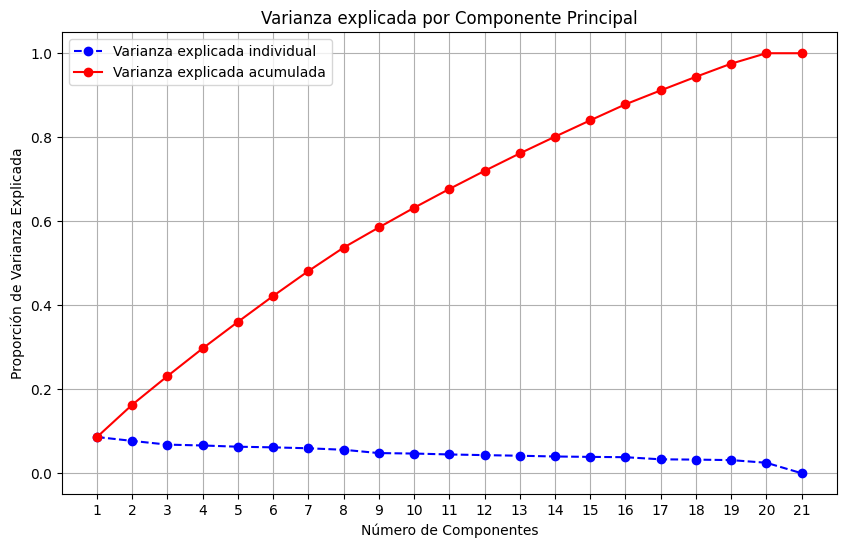

In [28]:
# Visualizar la varianza explicada
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio, marker='o', linestyle='--', color='blue')
plt.plot(range(1, len(cumulative_explained_variance) + 1), cumulative_explained_variance, marker='o', linestyle='-', color='red')
plt.title('Varianza explicada por Componente Principal')
plt.xlabel('Número de Componentes')
plt.ylabel('Proporción de Varianza Explicada')
plt.xticks(range(1, len(explained_variance_ratio) + 1))
plt.grid(True)
plt.legend(['Varianza explicada individual', 'Varianza explicada acumulada'])
plt.show()

### Matriz de Correlación de las Variables de Entrenamiento (post-escalado y balanceo)

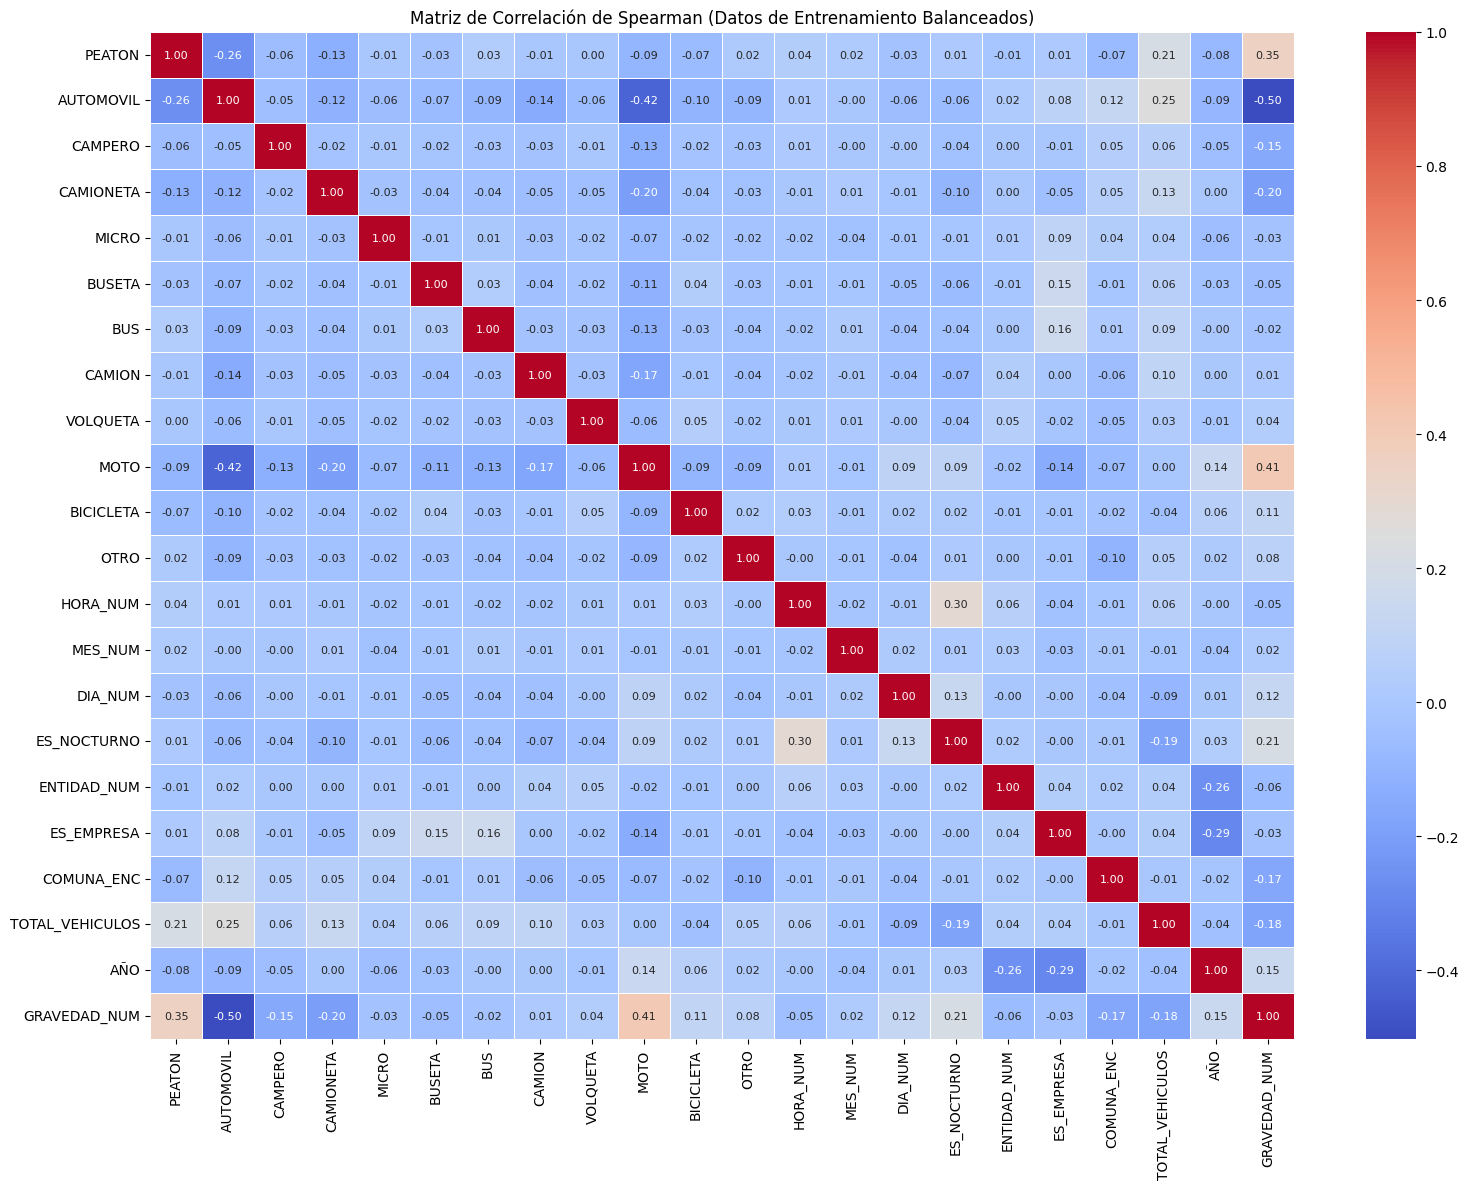


Correlaciones con GRAVEDAD_NUM (ordenadas):
MOTO               0.411
PEATON             0.349
ES_NOCTURNO        0.211
AÑO                0.146
DIA_NUM            0.121
BICICLETA          0.106
OTRO               0.076
VOLQUETA           0.037
MES_NUM            0.020
CAMION             0.010
BUS               -0.023
MICRO             -0.029
ES_EMPRESA        -0.032
HORA_NUM          -0.045
BUSETA            -0.052
ENTIDAD_NUM       -0.063
CAMPERO           -0.152
COMUNA_ENC        -0.168
TOTAL_VEHICULOS   -0.176
CAMIONETA         -0.202
AUTOMOVIL         -0.502
Name: GRAVEDAD_NUM, dtype: float64


In [29]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Crear un DataFrame con las características escaladas y balanceadas
df_train_bal = pd.DataFrame(X_train_bal, columns=features)
# Añadir la variable objetivo balanceada
df_train_bal['GRAVEDAD_NUM'] = y_train_bal

# Calcular la matriz de correlación
correlation_matrix_full = df_train_bal.corr(method='spearman')

plt.figure(figsize=(16, 12))
sns.heatmap(correlation_matrix_full, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=.5, annot_kws={'size': 8})
plt.title('Matriz de Correlación de Spearman (Datos de Entrenamiento Balanceados)')
plt.tight_layout()
plt.show()

print("\nCorrelaciones con GRAVEDAD_NUM (ordenadas):")
print(correlation_matrix_full['GRAVEDAD_NUM'].drop('GRAVEDAD_NUM').sort_values(ascending=False).round(3))

In [30]:
!pip install factor_analyzer

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for factor_analyzer: filename=factor_analyzer-0.5.1-py2.py3-none-any.whl size=42656 sha256=2a0ffdf34de79370694db93aaf5322900835da5effb030d9ada81b3f3b92bb92
  Stored in directory: /root/.cache/pip/wheels/87/6e/8f/914f20e0242ee0214e5c8336031a2fab12e632e4695fbb7276
Successfully built factor_analyzer


In [31]:
from factor_analyzer.factor_analyzer import calculate_kmo

# La prueba KMO se aplica sobre la matriz de correlación de las variables
# excluyendo la variable objetivo si se quiere evaluar la adecuación de las características.
# Usaremos la matriz de correlación calculada previamente.

# Obtener la matriz de correlación de solo las características
correlation_matrix_features = df_train_bal[features].corr()

# Reasignar los valores de retorno de calculate_kmo para corregir el orden
kmo_per_variable_values, kmo_overall_value = calculate_kmo(correlation_matrix_features)

print(f"Kaiser-Meyer-Olkin (KMO) test overall: {kmo_overall_value:.4f}")
print("\nKMO per variable:")
print(kmo_per_variable_values)

if kmo_overall_value >= 0.6:
    print("\nInterpretación: La adecuación muestral es meritoria (KMO >= 0.6), lo que sugiere que la Factor Analysis o PCA es apropiada.")
else:
    print("\nInterpretación: La adecuación muestral es pobre (KMO < 0.6), lo que sugiere que la Factor Analysis o PCA podría no ser apropiada.")

Kaiser-Meyer-Olkin (KMO) test overall: 0.3758

KMO per variable:
[0.40293017 0.57700891 0.21997537 0.39084377 0.27179782 0.42539025
 0.47421583 0.25292826 0.13406537 0.64282259 0.31906463 0.17278826
 0.42182543 0.10211534 0.37023591 0.43083643 0.30737348 0.42476195
 0.25426909 0.30065668 0.40883654]

Interpretación: La adecuación muestral es pobre (KMO < 0.6), lo que sugiere que la Factor Analysis o PCA podría no ser apropiada.


In [32]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Crear el dataset de regresión agrupando por las variables clave
df_reg_simple = df_model.groupby(['AÑO', 'MES_NUM', 'DIA_NUM', 'COMUNA_ENC', 'ES_NOCTURNO']).agg(
    FRECUENCIA_ACCIDENTES=('ORDEN', 'size')
).reset_index()

# Definir las características (X_reg_simple) y la variable objetivo (y_reg_simple)
features_reg_simple = ['AÑO', 'MES_NUM', 'DIA_NUM', 'COMUNA_ENC', 'ES_NOCTURNO']
X_reg_simple = df_reg_simple[features_reg_simple]
y_reg_simple = df_reg_simple['FRECUENCIA_ACCIDENTES']

# División de los datos en conjuntos de entrenamiento y prueba
X_train_reg_simple, X_test_reg_simple, y_train_reg_simple, y_test_reg_simple = train_test_split(
    X_reg_simple, y_reg_simple, test_size=0.2, random_state=42)

print(f"Dataset de Regresión simple creado: {df_reg_simple.shape[0]:,} registros")
print(f"X_train_reg_simple: {X_train_reg_simple.shape[0]:,} registros")
print(f"X_test_reg_simple:  {X_test_reg_simple.shape[0]:,} registros")

# Escalado de las características numéricas para regresión
scaler_reg_simple = StandardScaler()
X_train_reg_simple_sc = scaler_reg_simple.fit_transform(X_train_reg_simple)
X_test_reg_simple_sc = scaler_reg_simple.transform(X_test_reg_simple)

print("\nDatos de regresión con variables relevantes listos para modelado.")

Dataset de Regresión simple creado: 18,040 registros
X_train_reg_simple: 14,432 registros
X_test_reg_simple:  3,608 registros

Datos de regresión con variables relevantes listos para modelado.


### Regresión Lineal

In [33]:
from sklearn.linear_model import LinearRegression

# Modelo de Regresión Lineal
lin_reg_simple = LinearRegression()
res_lin_reg_simple = evaluar_regresor('Regresión Lineal (Simple Features)', lin_reg_simple, X_train_reg_simple_sc, y_train_reg_simple, X_test_reg_simple_sc, y_test_reg_simple)


  Regresión Lineal (Simple Features)
  MSE  : 2.8861
  RMSE : 1.6989
  MAE  : 1.2219
  R2   : 0.0875


### Random Forest Regressor

#### Optimización de Random Forest Regressor con RandomizedSearchCV

In [34]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
from sklearn.ensemble import RandomForestRegressor

# Definir la distribución de hiperparámetros para RandomizedSearchCV
param_dist_rf = {
    'n_estimators': randint(50, 200), # Número de árboles en el bosque
    'max_depth': randint(5, 30),      # Profundidad máxima de los árboles
    'min_samples_split': randint(2, 10), # Número mínimo de muestras requeridas para dividir un nodo
    'min_samples_leaf': randint(1, 5),   # Número mínimo de muestras requeridas para ser un nodo hoja
    'max_features': ['auto', 'sqrt', 'log2', 0.5, 0.75] # Número de características a considerar en cada división
}

# Inicializar el regresor base de Random Forest
rf_base = RandomForestRegressor(random_state=42)

# Configurar RandomizedSearchCV
random_search_rf = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist_rf,
    n_iter=50, # Número de combinaciones de hiperparámetros a probar
    cv=5,
    scoring='neg_mean_squared_error', # Métrica a optimizar (RMSE es preferible, pero RandomizedSearchCV usa MSE por defecto)
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Ejecutar la búsqueda aleatoria en los datos de entrenamiento
random_search_rf.fit(X_train_reg_simple_sc, y_train_reg_simple)

# Mostrar los mejores hiperparámetros encontrados
print(f"\nMejores hiperparámetros para Random Forest Regressor: {random_search_rf.best_params_}")

# Evaluar el mejor modelo encontrado
rf_optimized = random_search_rf.best_estimator_
res_rf_opt = evaluar_regresor('Random Forest Regressor Optimizado (RandomSearch)', rf_optimized, X_train_reg_simple_sc, y_train_reg_simple, X_test_reg_simple_sc, y_test_reg_simple)

Fitting 5 folds for each of 50 candidates, totalling 250 fits

Mejores hiperparámetros para Random Forest Regressor: {'max_depth': 10, 'max_features': 0.75, 'min_samples_leaf': 4, 'min_samples_split': 3, 'n_estimators': 188}

  Random Forest Regressor Optimizado (RandomSearch)
  MSE  : 1.5832
  RMSE : 1.2582
  MAE  : 0.8736
  R2   : 0.4995


### Comparación de Resultados de Regresión

In [35]:
resultados_regresion = pd.DataFrame([
    res_lin_reg_simple,
    res_rf_opt
])

print(resultados_regresion.sort_values(by='RMSE'))

                                              Modelo       MSE      RMSE  \
1  Random Forest Regressor Optimizado (RandomSearch)  1.583191  1.258249   
0                 Regresión Lineal (Simple Features)  2.886111  1.698856   

        MAE        R2  
1  0.873649  0.499454  
0  1.221861  0.087520  


### Predicción Interactiva con Random Forest Regressor

In [36]:
def predict_accident_frequency_simple(input_data: dict):
    """Realiza una predicción de la frecuencia de accidentes con el Random Forest Regressor
    usando el conjunto simplificado de características.

    Args:
        input_data (dict): Un diccionario con los valores para cada característica.
                           Las claves deben coincidir con las columnas usadas en el entrenamiento simple:
                           'AÑO', 'MES_NUM', 'DIA_NUM', 'COMUNA_ENC', 'ES_NOCTURNO'.

    Returns:
        float: La frecuencia de accidentes predicha.
    """
    # Crear un DataFrame con la entrada, asegurando el orden correcto de las columnas
    input_df = pd.DataFrame([input_data], columns=features_reg_simple)

    # Escalar los datos de entrada usando el scaler ya ajustado para las features simples
    input_scaled = scaler_reg_simple.transform(input_df)

    # Realizar la predicción
    prediction = rf_optimized.predict(input_scaled)

    return prediction[0]


print("Función 'predict_accident_frequency_simple' creada.")

Función 'predict_accident_frequency_simple' creada.


#### Ejemplo de Uso de la Función de Predicción Interactiva

In [37]:
# Definir un conjunto de datos de ejemplo para la predicción con las variables relevantes
example_input_simple = {
    'AÑO': 2023,
    'MES_NUM': 7,  # Julio
    'DIA_NUM': 15, # Día 15 del mes
    'COMUNA_ENC': 11, # Por ejemplo, '12. CABECERA DEL LLANO' codificada como 11
    'ES_NOCTURNO': 0 # Diurno (0 para diurno, 1 para nocturno)
}

# Realizar la predicción
predicted_frequency_simple = predict_accident_frequency_simple(example_input_simple)

print(f"La frecuencia de accidentes predicha para los valores de entrada simplificados es: {predicted_frequency_simple:.2f}")

La frecuencia de accidentes predicha para los valores de entrada simplificados es: 1.66
